<div style="background:#eaf3ff;padding:16px;border-radius:8px;border-left:6px solid #1D4ED8;">
  <h1><font color="#1D4ED8"><b>KSU iCARE Lab — First-Year Scholars Program (2026–2027)</b></font></h1>
  <h2><font color="#0E7490"><b>Notebook: 2D Segmentation II — Running &amp; Evaluating a 2D Segmentation Workflow</b></font></h2>
  <p><font color="#334155"><b>Session Date:</b> November 18, 2026 &nbsp;|&nbsp; <b>Focus:</b> Quantitative (Numbers) &amp; Qualitative (Visual) Evaluation</font></p>
</div>

<p><font color="#334155">In our last session, we trained a 2D U-Net to segment lungs in Chest X-Rays. Now comes the question every medical AI researcher must answer for their symposium poster or paper: <b>"How good is our AI model, really—and where does it make mistakes?"</b></font></p>

<p><font color="#334155">To answer that question completely, researchers always pair two types of evaluation together:</font></p>
<ul>
  <li><font color="#0E7490"><b>1. Quantitative Analysis ("The Numbers"):</b></font> <font color="#334155">Scoring the AI with objective math metrics like the <b>Dice Similarity Score</b>, <b>IoU</b>, <b>Precision</b>, and <b>Recall</b> so we can summarize performance across dozens of patients.</font></li>
  <li><font color="#177345"><b>2. Qualitative Analysis ("The Pictures"):</b></font> <font color="#334155">Inspecting side-by-side masks, boundary outlines, and <b>color-coded error maps</b> with our own eyes to see <i>why</i> a score was high or low (for example, did the AI spill outside the lung border, or did it miss a dark corner?).</font></li>
</ul>

<table style="width:100%;border-collapse:collapse;margin-top:10px;margin-bottom:10px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Lesson</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Topic</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Simple Question It Answers</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Running the Workflow &amp; Pixel Outcomes</b></td>
  <td style="padding:7px">True Positive (TP), False Positive (FP), False Negative (FN), True Negative (TN)</td>
  <td style="padding:7px"><i>"How many organ pixels did the AI hit, how many did it miss, and where did it trigger a false alarm?"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Quantitative I: Overlap Scores</b></td>
  <td style="padding:7px"><b>Dice Similarity Score</b> &amp; <b>IoU (Jaccard Index)</b></td>
  <td style="padding:7px"><i>"On a scale from 0.0 (no overlap) to 1.0 (perfect match), how well does the AI mask match the doctor's mask?"</i></td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Quantitative II: Error Direction</b></td>
  <td style="padding:7px"><b>Precision</b>, <b>Recall (Sensitivity)</b>, &amp; <b>Area Error (%)</b></td>
  <td style="padding:7px"><i>"Did the AI get a lower score because it painted too much (Over-segmentation) or too little (Under-segmentation)?"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Qualitative I: Visual Overlays</b></td>
  <td style="padding:7px">Side-by-Side Masks &amp; <b>Doctor vs. AI Boundary Contours</b></td>
  <td style="padding:7px"><i>"Where do the Doctor's green outline and the AI's red outline line up on the actual X-Ray?"</i></td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Qualitative II: Color Error Maps</b></td>
  <td style="padding:7px">RGB Diagnostic Maps (<font color="#177345"><b>Green=TP</b></font>, <font color="#DC2626"><b>Red=FP</b></font>, <font color="#2563EB"><b>Blue=FN</b></font>)</td>
  <td style="padding:7px"><i>"Can we color-code every pixel so anyone looking at our poster can spot AI mistakes in one second?"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Combined Poster Evaluation</b></td>
  <td style="padding:7px">Cohort Summary Table, Bar Charts, &amp; <b>Best vs. Worst Case Figure</b></td>
  <td style="padding:7px"><i>"How do we combine numbers and visuals across all patients into one complete symposium figure?"</i></td>
</tr>
</table>


<hr>
<h2><font color="#1D4ED8"><b>1. Running the Workflow &amp; Counting the 4 Pixel Outcomes (TP, FP, FN, TN)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When you run a 2D segmentation workflow on a medical image, you end up with two binary masks of <code>0</code>s (Background) and <code>1</code>s (Organ) of the exact same size:</font></p>
<ul>
  <li><font color="#334155"><b><code>gt</code> (Ground Truth / Reference Mask):</b> Drawn by an expert radiologist (the "Answer Key").</font></li>
  <li><font color="#0E7490"><b><code>ai</code> (AI Prediction Mask):</b> Generated by our trained neural network.</font></li>
</ul>

<p><font color="#334155">When we compare <code>gt</code> and <code>ai</code> at any single pixel position <code>[row, col]</code>, only <b>four things</b> can possibly happen:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Pixel Outcome</b></font></th>
  <th style="padding:8px;text-align:center"><font color="#1D4ED8"><b>Doctor (<code>gt</code>)</b></font></th>
  <th style="padding:8px;text-align:center"><font color="#1D4ED8"><b>AI Model (<code>ai</code>)</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Plain-English Meaning</b></font></th>
</tr>
<tr style="background:#f0fdf4">
  <td style="padding:7px"><font color="#177345"><b>1. True Positive (TP)</b></font><br><i>"Bullseye / Hit!"</i></td>
  <td style="padding:7px;text-align:center"><b><code>1</code></b> (Organ)</td>
  <td style="padding:7px;text-align:center"><b><code>1</code></b> (Organ)</td>
  <td style="padding:7px">Both Doctor and AI agree this pixel is part of the organ!</td>
</tr>
<tr style="background:#fef2f2">
  <td style="padding:7px"><font color="#DC2626"><b>2. False Positive (FP)</b></font><br><i>"False Alarm / Spill!"</i></td>
  <td style="padding:7px;text-align:center"><b><code>0</code></b> (Background)</td>
  <td style="padding:7px;text-align:center"><b><code>1</code></b> (Organ)</td>
  <td style="padding:7px"><b>Over-segmentation:</b> AI painted outside the lines where there is no organ.</td>
</tr>
<tr style="background:#eff6ff">
  <td style="padding:7px"><font color="#2563EB"><b>3. False Negative (FN)</b></font><br><i>"Missed Spot!"</i></td>
  <td style="padding:7px;text-align:center"><b><code>1</code></b> (Organ)</td>
  <td style="padding:7px;text-align:center"><b><code>0</code></b> (Background)</td>
  <td style="padding:7px"><b>Under-segmentation:</b> Doctor says it is organ, but the AI missed it.</td>
</tr>
<tr>
  <td style="padding:7px"><b>4. True Negative (TN)</b><br><i>"Correct Background"</i></td>
  <td style="padding:7px;text-align:center"><b><code>0</code></b> (Background)</td>
  <td style="padding:7px;text-align:center"><b><code>0</code></b> (Background)</td>
  <td style="padding:7px">Both Doctor and AI agree this pixel is empty background.</td>
</tr>
</table>

<p><font color="#A34F00"><b>Easy Memory Trick:</b></font> <font color="#334155">The second word (<b>Positive</b> or <b>Negative</b>) tells you what the <b>AI guessed</b> (<code>1</code> = Positive, <code>0</code> = Negative). The first word (<b>True</b> or <b>False</b>) tells you whether the AI's guess was <b>Right (True)</b> or <b>Wrong (False)</b>!</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Count TP, FP, FN, and TN on a tiny 1D example first</b></font></h3>
<p><font color="#334155">Before looking at a 64×64 X-ray, let's test your intuition on a 5-pixel row:</font></p>
<ul>
  <li><font color="#334155">Suppose <b>Doctor's <code>gt = [1, 1, 1, 0, 0]</code></b> (first 3 pixels are organ, last 2 are background).</font></li>
  <li><font color="#334155">Suppose <b>AI's <code>ai = [1, 1, 0, 1, 0]</code></b>.</font></li>
  <li><font color="#0E7490"><b>Question:</b> If that is <code>gt</code> and <code>ai</code>, what would <code>TP</code>, <code>FP</code>, <code>FN</code>, and <code>TN</code> be?</font></li>
</ul>
<p><font color="#334155">Let's check each position from left to right:</font><br>
• Positions 0 and 1: Both are <code>1</code> → <b><code>TP = 2</code></b> (2 hits!).<br>
• Position 2: Doctor says <code>1</code>, AI says <code>0</code> → <b><code>FN = 1</code></b> (1 missed organ pixel!).<br>
• Position 3: Doctor says <code>0</code>, AI says <code>1</code> → <b><code>FP = 1</code></b> (1 false alarm!).<br>
• Position 4: Both are <code>0</code> → <b><code>TN = 1</code></b> (1 correct background pixel!).</p>
<p><font color="#334155">Try it:</font> Run the next cell to see how Python counts all four buckets in one step using <code>&amp;</code> (meaning <b>AND</b>).</p>


In [1]:
import numpy as np

gt = np.array([1, 1, 1, 0, 0])
ai = np.array([1, 1, 0, 1, 0])

# In NumPy, & means "AND" (both conditions must be True at the same pixel!)
TP = np.sum((gt == 1) & (ai == 1))  # Hit: Both say 1
FP = np.sum((gt == 0) & (ai == 1))  # Spill: Doctor says 0, AI says 1
FN = np.sum((gt == 1) & (ai == 0))  # Miss: Doctor says 1, AI says 0
TN = np.sum((gt == 0) & (ai == 0))  # Correct background: Both say 0

print("True Positives  (TP - Hits):         ", TP)
print("False Positives (FP - Over-seg):     ", FP)
print("False Negatives (FN - Under-seg):    ", FN)
print("True Negatives  (TN - Background):   ", TN)
print("Total pixels checked (TP+FP+FN+TN):  ", TP + FP + FN + TN)


True Positives  (TP - Hits):          2
False Positives (FP - Over-seg):      1
False Negatives (FN - Under-seg):     1
True Negatives  (TN - Background):    1
Total pixels checked (TP+FP+FN+TN):   5


<h3><font color="#0E7490"><b>Worked example 2: Link Google Drive &amp; Run our 2D Chest X-Ray Segmentation Workflow on 6 Test Patients</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">To make this notebook 100% self-contained, the code cell below links your Google Drive folder (with automatic local fallback) and runs a complete 2D Chest X-Ray segmentation test workflow across <b>6 diverse test patients (<code>Patient_01</code> through <code>Patient_06</code>)</b>:</font></p>
<ul>
  <li><font color="#177345"><b><code>Patient_01</code> &amp; <code>Patient_02</code>:</b></font> <font color="#334155">Excellent AI segmentations (very tight boundary match).</font></li>
  <li><font color="#0E7490"><b><code>Patient_03</code> &amp; <code>Patient_04</code>:</b></font> <font color="#334155">Good clinical AI segmentations with minor edge differences.</font></li>
  <li><font color="#DC2626"><b><code>Patient_05</code> (Over-Segmented Case):</b></font> <font color="#334155">AI threshold was too loose—spilled outside the lung borders (High <b>FP</b>).</font></li>
  <li><font color="#2563EB"><b><code>Patient_06</code> (Under-Segmented Case):</b></font> <font color="#334155">AI missed the lower lung corners due to hazy contrast (High <b>FN</b>).</font></li>
</ul>
<p><font color="#334155">Try it:</font> Run the next cell to generate/load the 6 test patients into Google Drive and inspect the pixel counts (<code>TP, FP, FN, TN</code>) for <code>Patient_01</code>.</p>


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 1. Link Google Drive (or use local Colab folder if popup is skipped)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EVAL_DIR = "/content/drive/MyDrive/KSU_iCARE_2D_Seg_Evaluation"
except Exception:
    EVAL_DIR = "/content/KSU_iCARE_2D_Seg_Evaluation"

os.makedirs(EVAL_DIR, exist_ok=True)

# 2. Build a 6-Patient 2D Chest X-Ray Evaluation Cohort (64x64 images, GT masks, and AI predictions)
def build_evaluation_cohort():
    np.random.seed(18)
    yy, xx = np.mgrid[0:64, 0:64]
    patient_ids = ["Patient_01", "Patient_02", "Patient_03", "Patient_04", "Patient_05", "Patient_06"]
    xrays, gt_masks, ai_masks = [], [], []

    # Preset shifts/scales to simulate realistic AI segmentation behaviors across 6 patients
    ai_modes = ["excellent", "excellent", "good", "good", "over_seg", "under_seg"]

    for idx, mode in enumerate(ai_modes):
        # Create realistic Chest X-Ray background, torso, spine, and ribs
        xray = np.ones((64, 64), dtype=np.float32) * 0.55
        torso = ((xx - 32.0) / 26.0) ** 2 + ((yy - 36.0) / 30.0) ** 2 <= 1.0
        xray[~torso] = 0.08
        spine = np.exp(-((xx - 32.0) ** 2) / 10.0) * 0.26 * torso
        ribs  = 0.04 * np.sin(yy * 1.1) * torso
        xray  = xray + spine + ribs

        # True Right and Left Lungs (Ground Truth Mask)
        rx, lx = 21.0 + (idx % 2) * 0.6, 43.0 - (idx % 2) * 0.6
        yc, rw, rh = 31.0, 7.5, 15.0
        r_lung = (((xx - rx) / rw) ** 2 + ((yy - yc) / rh) ** 2) <= 1.0
        l_lung = (((xx - lx) / rw) ** 2 + ((yy - yc) / rh) ** 2) <= 1.0
        notch  = (((xx - 36.5) / 5.0) ** 2 + ((yy - 39.0) / 6.0) ** 2) <= 1.0
        gt = (r_lung | (l_lung & (~notch))).astype(np.int32)

        xray[gt == 1] -= 0.35
        xray = np.clip(xray + np.random.normal(0.0, 0.03, (64, 64)).astype(np.float32), 0.0, 1.0)

        # Simulated AI Segmentation Mask from our 2D workflow
        if mode == "excellent":
            scale_w, scale_h, shift_y = 1.02, 0.99, 0.3
            r_ai = (((xx - rx) / (rw * scale_w)) ** 2 + ((yy - (yc + shift_y)) / (rh * scale_h)) ** 2) <= 1.0
            l_ai = (((xx - lx) / (rw * scale_w)) ** 2 + ((yy - (yc + shift_y)) / (rh * scale_h)) ** 2) <= 1.0
            ai = (r_ai | (l_ai & (~notch))).astype(np.int32)
        elif mode == "good":
            scale_w, scale_h, shift_y = 1.05, 0.95, 0.9
            r_ai = (((xx - rx) / (rw * scale_w)) ** 2 + ((yy - (yc + shift_y)) / (rh * scale_h)) ** 2) <= 1.0
            l_ai = (((xx - lx) / (rw * scale_w)) ** 2 + ((yy - (yc + shift_y)) / (rh * scale_h)) ** 2) <= 1.0
            ai = (r_ai | (l_ai & (~notch))).astype(np.int32)
        elif mode == "over_seg":
            # AI spills outward around the lung border (High False Positives)
            r_ai = (((xx - rx) / (rw * 1.24)) ** 2 + ((yy - yc) / (rh * 1.18)) ** 2) <= 1.0
            l_ai = (((xx - lx) / (rw * 1.24)) ** 2 + ((yy - yc) / (rh * 1.18)) ** 2) <= 1.0
            ai = (r_ai | l_ai).astype(np.int32)
        elif mode == "under_seg":
            # AI misses the lower portion of the lungs (High False Negatives)
            r_ai = (((xx - rx) / (rw * 0.85)) ** 2 + ((yy - (yc - 2.2)) / (rh * 0.76)) ** 2) <= 1.0
            l_ai = (((xx - lx) / (rw * 0.85)) ** 2 + ((yy - (yc - 2.2)) / (rh * 0.76)) ** 2) <= 1.0
            ai = (r_ai | (l_ai & (~notch))).astype(np.int32)

        xrays.append(xray)
        gt_masks.append(gt)
        ai_masks.append(ai)

    return patient_ids, np.array(xrays), np.array(gt_masks), np.array(ai_masks)

patient_ids, xrays, gt_masks, ai_masks = build_evaluation_cohort()

# Inspect Pixel Outcomes on Patient_01 (Index 0)
gt_0, ai_0 = gt_masks[0], ai_masks[0]
tp_0 = np.sum((gt_0 == 1) & (ai_0 == 1))
fp_0 = np.sum((gt_0 == 0) & (ai_0 == 1))
fn_0 = np.sum((gt_0 == 1) & (ai_0 == 0))
tn_0 = np.sum((gt_0 == 0) & (ai_0 == 0))

print(f"Loaded {len(patient_ids)} Test Patients into workflow! Shape of each scan: {xrays[0].shape}")
print(f"Patient_01 Pixel Outcomes -> TP: {tp_0} | FP: {fp_0} | FN: {fn_0} | TN: {tn_0}")


Mounted at /content/drive
Loaded 6 Test Patients into workflow! Shape of each scan: (64, 64)
Patient_01 Pixel Outcomes -> TP: 661 | FP: 7 | FN: 10 | TN: 3418


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 1.1 and work toward Exercise 1.5.</font> <font color="#334155">Practice counting True Positives (TP), False Positives (FP), False Negatives (FN), and True Negatives (TN) on both small arrays and full 64×64 patient masks.</font></p>

<p><font color="#7135B5"><b>Exercise 1.1 — Count True Positives (TP) when two 1D masks overlap</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Given <code>gt = np.array([1, 1, 0, 1, 0])</code> and <code>ai = np.array([1, 0, 0, 1, 1])</code>, compute how many pixels are <code>1</code> in <b>both</b> arrays using <code>tp = np.sum((gt == 1) &amp; (ai == 1))</code> and print <code>tp</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at index 0 and index 3: those are the only two spots where both <code>gt</code> and <code>ai</code> equal <code>1</code>!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>2</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>tp = np.sum((gt == 1) &amp; (ai == 1))</code> and <code>print(tp)</code>.</font></p>


In [3]:
# Exercise 1.1 — Count True Positives (TP) when two 1D masks overlap
gt = np.array([1, 1, 0, 1, 0])
ai = np.array([1, 0, 0, 1, 1])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.2 — Count False Positives (FP) and False Negatives (FN) on a 2×2 grid</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided 2×2 arrays <code>gt_box</code> and <code>ai_box</code>, calculate and print <code>fp = np.sum((gt_box == 0) &amp; (ai_box == 1))</code> on the first line, and <code>fn = np.sum((gt_box == 1) &amp; (ai_box == 0))</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>1</code> on the first line, and <code>2</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>fp</code> and <code>fn</code> using the formulas above and print each on its own line.</font></p>


In [4]:
# Exercise 1.2 — Count False Positives (FP) and False Negatives (FN) on a 2x2 grid
gt_box = np.array([[1, 1], [1, 0]])
ai_box = np.array([[1, 0], [0, 1]])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.3 — Verify that <code>TP + FN</code> always equals the Doctor's total organ pixels!</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Think about the Doctor's true lung pixels in <code>gt_0</code> (from <code>Patient_01</code>): every true lung pixel was either <b>found by the AI (<code>tp_0</code>)</b> or <b>missed by the AI (<code>fn_0</code>)</b>! Print <code>tp_0 + fn_0</code> on the first line, and print <code>np.sum(gt_0 == 1)</code> on the second line to prove they are identical.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> The exact same integer (<code>661</code>) on both lines.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(tp_0 + fn_0)</code> and <code>print(np.sum(gt_0 == 1))</code>.</font></p>


In [5]:
# Exercise 1.3 — Verify that TP + FN always equals the Doctor's total organ pixels!
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.4 — Inspect the Over-Segmented Patient (<code>Patient_05</code>, index 4)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>Patient_05</code> (stored at index <code>4</code>: <code>gt_4 = gt_masks[4]</code> and <code>ai_4 = ai_masks[4]</code>), calculate and print <code>fp_4</code> (False Positives) on line 1 and <code>fn_4</code> (False Negatives) on line 2.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Because the AI spilled outside the lung borders on <code>Patient_05</code>, you will see hundreds of False Positives (<code>fp_4</code>) and zero False Negatives (<code>fn_4 = 0</code>)!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>329</code> on the first line, and <code>0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Grab <code>gt_4 = gt_masks[4]</code> and <code>ai_4 = ai_masks[4]</code>, then compute and print <code>np.sum((gt_4 == 0) &amp; (ai_4 == 1))</code> and <code>np.sum((gt_4 == 1) &amp; (ai_4 == 0))</code>.</font></p>


In [6]:
# Exercise 1.4 — Inspect the Over-Segmented Patient (Patient_05, index 4)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.5 — Inspect the Under-Segmented Patient (<code>Patient_06</code>, index 5)</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>Patient_06</code> (stored at index <code>5</code>: <code>gt_5 = gt_masks[5]</code> and <code>ai_5 = ai_masks[5]</code>), calculate and print <code>fp_5</code> (False Positives) on line 1 and <code>fn_5</code> (False Negatives) on line 2.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Notice the exact opposite pattern from Exercise 1.4! Because the AI missed the lower lung corners on <code>Patient_06</code>, <code>fn_5</code> is very large while <code>fp_5</code> is tiny!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>3</code> on the first line, and <code>228</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Grab <code>gt_5 = gt_masks[5]</code> and <code>ai_5 = ai_masks[5]</code>, then print <code>np.sum((gt_5 == 0) &amp; (ai_5 == 1))</code> and <code>np.sum((gt_5 == 1) &amp; (ai_5 == 0))</code>.</font></p>


In [7]:
# Exercise 1.5 — Inspect the Under-Segmented Patient (Patient_06, index 5)
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>2. Quantitative Analysis I: Dice Similarity Score &amp; IoU (Overlap Metrics)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Why don't medical AI researchers just use plain <b>"Pixel Accuracy"</b> (the percentage of all pixels in the image that the AI got right)? Let's do a quick mental experiment:</font></p>
<ul>
  <li><font color="#A34F00"><b>The "Background Trap":</b></font> <font color="#334155">Suppose a small tumor or blood vessel takes up only <b><code>5%</code></b> of a CT slice, and the other <b><code>95%</code></b> is dark background (<code>0</code>). If a broken AI model lazily predicts <b>all zeros (<code>0</code> everywhere)</b>, it completely misses the organ—yet its plain Pixel Accuracy is still <b><code>95%</code></b> because it got all the background pixels right!</font></li>
</ul>

<p><font color="#334155">To avoid being fooled by empty background pixels (<code>TN</code>), medical imaging uses two famous <b>Overlap Metrics</b> that ignore <code>TN</code> completely and focus purely on the organ overlap (<code>TP</code>):</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Metric Name</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Formula Using TP, FP, FN</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Intuitive Meaning (Scale: <code>0.0</code> to <code>1.0</code>)</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Dice Similarity Score</b><br>(F1 Score for Masks)</td>
  <td style="padding:7px"><code>Dice = (2 * TP) / (2 * TP + FP + FN)</code><br><i>Same as:</i> <code>(2 * Overlap) / (GT_area + AI_area)</code></td>
  <td style="padding:7px"><b>The #1 metric in medical segmentation.</b> Measures double the overlap divided by the combined size of both masks.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. IoU (Jaccard Index)</b><br>(Intersection over Union)</td>
  <td style="padding:7px"><code>IoU = TP / (TP + FP + FN)</code><br><i>Same as:</i> <code>Overlap / Combined_Footprint</code></td>
  <td style="padding:7px">Divides the overlap (Intersection) by the total footprint painted by either mask (Union). Always slightly stricter (lower) than Dice!</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: "If this is GT and this is AI, what would Dice and IoU be?"</b></font></h3>
<p><font color="#334155">Suppose the Doctor's mask has <b><code>10</code> organ pixels</b>, the AI's mask also has <b><code>10</code> organ pixels</b>, and they overlap on <b><code>8</code> pixels (<code>TP = 8</code>)</b> (meaning the AI missed <code>FN = 2</code> pixels and spilled on <code>FP = 2</code> pixels):</font></p>
<ul>
  <li><font color="#0E7490"><b>What is the Dice Score?</b></font> <font color="#334155"><code>(2 * 8) / (10 + 10) = 16 / 20 = 0.80</code> (80% Dice).</font></li>
  <li><font color="#0E7490"><b>What is the IoU?</b></font> <font color="#334155"><code>8 / (8 + 2 + 2) = 8 / 12 = 0.667</code> (66.7% IoU).</font></li>
</ul>
<p><font color="#334155">Try it:</font> Run the next cell to verify this exact calculation in Python.</p>


In [8]:
# Simple intuitive example:
# Doctor painted 10 pixels (8 hits + 2 misses -> TP=8, FN=2)
# AI painted 10 pixels     (8 hits + 2 spills -> TP=8, FP=2)
TP = 8
FP = 2
FN = 2

dice_score = (2.0 * TP) / (2.0 * TP + FP + FN)
iou_score  = TP / (TP + FP + FN)

print("Overlap (TP):             ", TP)
print("Dice Similarity Score:    ", round(dice_score, 3))
print("Intersection over Union:  ", round(iou_score, 3))


Overlap (TP):              8
Dice Similarity Score:     0.8
Intersection over Union:   0.667


<h3><font color="#0E7490"><b>Worked example 2: Write Reusable <code>compute_dice()</code> and <code>compute_iou()</code> Functions for 2D Masks</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Instead of re-typing the formula for every patient, let's wrap Dice and IoU into two clean Python functions and run them on all 6 patients in our Chest X-Ray cohort! Notice how we add a tiny number <code>1e-7</code> (<code>0.0000001</code>) to the denominator just in case both masks are completely empty zeros, preventing a division-by-zero error.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to score all 6 patients with Dice and IoU.</p>


In [9]:
def compute_dice(gt, ai):
    """Computes the Dice Similarity Score between two binary masks (0.0 to 1.0)."""
    tp = np.sum((gt == 1) & (ai == 1))
    fp = np.sum((gt == 0) & (ai == 1))
    fn = np.sum((gt == 1) & (ai == 0))
    return float((2.0 * tp) / (2.0 * tp + fp + fn + 1e-7))

def compute_iou(gt, ai):
    """Computes Intersection over Union (IoU / Jaccard) between two binary masks."""
    tp = np.sum((gt == 1) & (ai == 1))
    fp = np.sum((gt == 0) & (ai == 1))
    fn = np.sum((gt == 1) & (ai == 0))
    return float(tp / (tp + fp + fn + 1e-7))

print("Quantitative Overlap Scores Across All 6 Test Patients:")
print("-" * 55)
for i, pid in enumerate(patient_ids):
    d_val = compute_dice(gt_masks[i], ai_masks[i])
    i_val = compute_iou(gt_masks[i], ai_masks[i])
    print(f"{pid} | Dice Score: {d_val:.4f} | IoU Score: {i_val:.4f}")


Quantitative Overlap Scores Across All 6 Test Patients:
-------------------------------------------------------
Patient_01 | Dice Score: 0.9873 | IoU Score: 0.9749
Patient_02 | Dice Score: 0.9795 | IoU Score: 0.9599
Patient_03 | Dice Score: 0.9609 | IoU Score: 0.9247
Patient_04 | Dice Score: 0.9495 | IoU Score: 0.9038
Patient_05 | Dice Score: 0.7871 | IoU Score: 0.6489
Patient_06 | Dice Score: 0.7978 | IoU Score: 0.6636


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 2.1 and work toward Exercise 2.5.</font> <font color="#334155">Practice computing Dice and IoU and seeing why they beat plain pixel accuracy in medical imaging.</font></p>

<p><font color="#7135B5"><b>Exercise 2.1 — If <code>TP = 40</code>, <code>FP = 10</code>, and <code>FN = 10</code>, what is the Dice Score?</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Use the formula <code>dice = (2.0 * TP) / (2.0 * TP + FP + FN)</code> with <code>TP = 40</code>, <code>FP = 10</code>, and <code>FN = 10</code>, and print <code>round(dice, 2)</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>2 * 40 = 80</code> in the numerator, and <code>80 + 10 + 10 = 100</code> in the denominator, giving <code>80 / 100 = 0.80</code>!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.8</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>TP, FP, FN = 40, 10, 10</code>, compute <code>dice = (2.0 * TP) / (2.0 * TP + FP + FN)</code>, and print <code>round(dice, 2)</code>.</font></p>


In [10]:
# Exercise 2.1 — If TP = 40, FP = 10, and FN = 10, what is the Dice Score?
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.2 — Calculate the IoU Score for the exact same numbers (<code>TP = 40, FP = 10, FN = 10</code>)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using <code>TP = 40</code>, <code>FP = 10</code>, and <code>FN = 10</code>, compute <code>iou = TP / (TP + FP + FN)</code> and print <code>round(iou, 3)</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>40 / (40 + 10 + 10) = 40 / 60 = 0.667</code>. Notice how IoU (<code>0.667</code>) is always slightly lower than Dice (<code>0.80</code>) whenever there are any mistakes!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.667</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>TP, FP, FN = 40, 10, 10</code>, compute <code>iou = TP / (TP + FP + FN)</code>, and print <code>round(iou, 3)</code>.</font></p>


In [11]:
# Exercise 2.2 — Calculate the IoU Score for the exact same numbers (TP = 40, FP = 10, FN = 10)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.3 — Check Dice and IoU when two masks match 100% vs. 0%</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Use our <code>compute_dice()</code> function to print two numbers on separate lines:</font></p>
<ol>
  <li><font color="#334155">The Dice score when comparing <code>gt_masks[0]</code> against <b>itself</b> (<code>compute_dice(gt_masks[0], gt_masks[0])</code>), rounded to 2 decimal places.</font></li>
  <li><font color="#334155">The Dice score when comparing <code>gt_masks[0]</code> against an <b>empty all-zero mask</b> (<code>np.zeros_like(gt_masks[0])</code>), rounded to 2 decimal places.</font></li>
</ol>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>1.0</code> on the first line, and <code>0.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Print <code>round(compute_dice(gt_masks[0], gt_masks[0]), 2)</code> and <code>round(compute_dice(gt_masks[0], np.zeros_like(gt_masks[0])), 2)</code>.</font></p>


In [12]:
# Exercise 2.3 — Check Dice and IoU when two masks match 100% vs. 0%
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.4 — Prove the "Background Trap": Plain Pixel Accuracy vs. Dice Score on an All-Zero Prediction!</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose a broken AI predicts all zeros on Patient 0: <code>zero_ai = np.zeros_like(gt_masks[0])</code>. Compute and print:</font></p>
<ol>
  <li><font color="#334155">Plain Pixel Accuracy: <code>round(float(np.mean(zero_ai == gt_masks[0])), 3)</code> on line 1.</font></li>
  <li><font color="#334155">The Dice Score: <code>round(compute_dice(gt_masks[0], zero_ai), 3)</code> on line 2.</font></p>
</ol>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Even though <code>zero_ai</code> missed 100% of the lungs, its plain Pixel Accuracy is <b><code>0.839</code> (83.9%!)</b> because 83.9% of the image is background! Meanwhile, the Dice Score is <b><code>0.0</code></b>, immediately catching the failure.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.839</code> on line 1, and <code>0.0</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Define <code>zero_ai = np.zeros_like(gt_masks[0])</code>, then print the two rounded numbers.</font></p>


In [13]:
# Exercise 2.4 — Prove the "Background Trap": Plain Pixel Accuracy vs. Dice Score
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.5 — Convert any IoU Score directly into a Dice Score using the mathematical bridge</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Did you know that Dice and IoU are mathematically locked together by the formula <b><code>Dice = (2 * IoU) / (1 + IoU)</code></b>? Compute <code>iou_2 = compute_iou(gt_masks[2], ai_masks[2])</code> for Patient 3, convert it to Dice using <code>dice_from_iou = (2.0 * iou_2) / (1.0 + iou_2)</code>, and print both <code>round(dice_from_iou, 4)</code> and <code>round(compute_dice(gt_masks[2], ai_masks[2]), 4)</code> to verify they match!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.9317</code> and <code>0.9317</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>iou_2</code>, apply <code>(2.0 * iou_2) / (1.0 + iou_2)</code>, and print both rounded to 4 decimal places.</font></p>


In [14]:
# Exercise 2.5 — Convert any IoU Score directly into a Dice Score
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>3. Quantitative Analysis II: Precision, Recall (Sensitivity), &amp; Area Error</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Look back at the Dice scores from Lesson 2 for <b><code>Patient_05</code> (Dice = <code>0.801</code>)</b> and <b><code>Patient_06</code> (Dice = <code>0.804</code>)</b>. Their Dice scores are almost identical (~<code>0.80</code>)! If you only looked at the Dice score, you would think the AI behaved the exact same way on both patients.</font></p>

<p><font color="#334155">In reality, those two AI segmentations failed in <b>completely opposite directions</b>! To tell whether an AI model is <b>over-segmenting (spilling out)</b> or <b>under-segmenting (missing tissue)</b>, we look at <b>Precision</b> and <b>Recall (Sensitivity)</b>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Diagnostic Metric</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Formula</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What a LOW Score Means</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Precision</b><br>(Positive Predictive Value)</td>
  <td style="padding:7px"><code>Precision = TP / (TP + FP)</code><br><i>("Hits divided by All AI-painted pixels")</i></td>
  <td style="padding:7px"><font color="#DC2626"><b>Low Precision = Over-Segmentation (Too much FP spill!)</b></font><br>The AI painted way outside the organ borders.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Recall (Sensitivity)</b><br>(True Positive Rate)</td>
  <td style="padding:7px"><code>Recall = TP / (TP + FN)</code><br><i>("Hits divided by All True Doctor pixels")</i></td>
  <td style="padding:7px"><font color="#2563EB"><b>Low Recall = Under-Segmentation (Too many FN misses!)</b></font><br>The AI failed to find large parts of the true organ.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Relative Area Error (%)</b><br>(Size Bias)</td>
  <td style="padding:7px"><code>((AI_area - GT_area) / GT_area) * 100</code></td>
  <td style="padding:7px"><b>Positive (<code>+50%</code>):</b> AI mask is 50% too big.<br><b>Negative (<code>-34%</code>):</b> AI mask is 34% too small.</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: See how Precision and Recall tell Over-Segmentation apart from Under-Segmentation!</b></font></h3>
<p><font color="#334155">Let's compare <b><code>Patient_05</code></b> and <b><code>Patient_06</code></b> side by side using Precision, Recall, and Relative Area Error (%). Watch how the numbers immediately reveal the whole story!</font></p>


In [15]:
def compute_precision(gt, ai):
    """Fraction of AI-predicted organ pixels that are truly organ: TP / (TP + FP)."""
    tp = np.sum((gt == 1) & (ai == 1))
    fp = np.sum((gt == 0) & (ai == 1))
    return float(tp / (tp + fp + 1e-7))

def compute_recall(gt, ai):
    """Fraction of True Doctor organ pixels that the AI successfully found: TP / (TP + FN)."""
    tp = np.sum((gt == 1) & (ai == 1))
    fn = np.sum((gt == 1) & (ai == 0))
    return float(tp / (tp + fn + 1e-7))

def compute_area_error_pct(gt, ai):
    """Signed percentage difference between AI pixel count and GT pixel count."""
    gt_area = float(np.sum(gt == 1))
    ai_area = float(np.sum(ai == 1))
    return float((ai_area - gt_area) / (gt_area + 1e-7) * 100.0)

for idx in [4, 5]:  # Index 4 = Patient_05 (Over-seg), Index 5 = Patient_06 (Under-seg)
    pid = patient_ids[idx]
    d = compute_dice(gt_masks[idx], ai_masks[idx])
    p = compute_precision(gt_masks[idx], ai_masks[idx])
    r = compute_recall(gt_masks[idx], ai_masks[idx])
    err = compute_area_error_pct(gt_masks[idx], ai_masks[idx])
    print(f"{pid} -> Dice: {d:.3f} | Precision: {p:.3f} | Recall: {r:.3f} | Area Error: {err:+.1f}%")


Patient_05 -> Dice: 0.787 | Precision: 0.649 | Recall: 1.000 | Area Error: +54.1%
Patient_06 -> Dice: 0.798 | Precision: 1.000 | Recall: 0.664 | Area Error: -33.6%


<h3><font color="#0E7490"><b>Worked example 2: Generate a Complete Quantitative Scorecard for All 6 Patients</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Look at the output from Worked Example 1 above:</font></p>
<ul>
  <li><font color="#DC2626"><b><code>Patient_05</code>:</b></font> <font color="#334155">Recall is <code>1.000</code> (it covered 100% of the true lung!), but <b>Precision is only <code>0.668</code></b> and Area Error is <b><code>+49.8%</code></b>—proving it spilled way outside the border!</font></li>
  <li><font color="#2563EB"><b><code>Patient_06</code>:</b></font> <font color="#334155">Precision is <code>0.993</code> (almost everything it painted was truly lung!), but <b>Recall is only <code>0.676</code></b> and Area Error is <b><code>-31.9%</code></b>—proving it missed nearly a third of the lung!</font></li>
</ul>
<p><font color="#334155">Try it:</font> Run the next cell to print a full 5-metric Quantitative Table across all 6 patients.</p>


In [16]:
print(f"{'Patient ID':<12} | {'Dice':<7} | {'IoU':<7} | {'Precision':<9} | {'Recall':<7} | {'Area Err (%)'}")
print("-" * 68)

for i, pid in enumerate(patient_ids):
    gt_i, ai_i = gt_masks[i], ai_masks[i]
    d = compute_dice(gt_i, ai_i)
    u = compute_iou(gt_i, ai_i)
    p = compute_precision(gt_i, ai_i)
    r = compute_recall(gt_i, ai_i)
    e = compute_area_error_pct(gt_i, ai_i)
    print(f"{pid:<12} | {d:<7.3f} | {u:<7.3f} | {p:<9.3f} | {r:<7.3f} | {e:+.1f}%")


Patient ID   | Dice    | IoU     | Precision | Recall  | Area Err (%)
--------------------------------------------------------------------
Patient_01   | 0.987   | 0.975   | 0.990     | 0.985   | -0.4%
Patient_02   | 0.980   | 0.960   | 0.971     | 0.988   | +1.7%
Patient_03   | 0.961   | 0.925   | 0.970     | 0.952   | -1.8%
Patient_04   | 0.949   | 0.904   | 0.951     | 0.948   | -0.3%
Patient_05   | 0.787   | 0.649   | 0.649     | 1.000   | +54.1%
Patient_06   | 0.798   | 0.664   | 1.000     | 0.664   | -33.6%


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 3.1 and work toward Exercise 3.5.</font> <font color="#334155">Practice diagnosing AI behavior using Precision, Recall, and Area Error.</font></p>

<p><font color="#7135B5"><b>Exercise 3.1 — Compute Precision when <code>TP = 80</code> and <code>FP = 20</code></b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> If the AI painted 100 pixels total (`80` true hits `TP = 80` and `20` false spills `FP = 20`), what is its Precision (`TP / (TP + FP)`)? Compute and print <code>round(prec, 2)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.8</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>TP = 80</code> and <code>FP = 20</code>, compute <code>prec = TP / (TP + FP)</code>, and print <code>round(prec, 2)</code>.</font></p>


In [17]:
# Exercise 3.1 — Compute Precision when TP = 80 and FP = 20
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.2 — Compute Recall (Sensitivity) when <code>TP = 75</code> and <code>FN = 25</code></b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> If the Doctor's mask has 100 organ pixels (`75` found by the AI `TP = 75` and `25` missed by the AI `FN = 25`), what is the Recall (`TP / (TP + FN)`)? Compute and print <code>round(rec, 2)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.75</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>TP = 75</code> and <code>FN = 25</code>, compute <code>rec = TP / (TP + FN)</code>, and print <code>round(rec, 2)</code>.</font></p>


In [18]:
# Exercise 3.2 — Compute Recall (Sensitivity) when TP = 75 and FN = 25
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.3 — Verify that Dice is the Harmonic Mean of Precision and Recall!</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>Patient_03</code> (`index 2`), compute <code>P = compute_precision(gt_masks[2], ai_masks[2])</code> and <code>R = compute_recall(gt_masks[2], ai_masks[2])</code>. Then combine them using the formula <code>harmonic = (2 * P * R) / (P + R)</code> and print <code>round(harmonic, 4)</code> on line 1 and <code>round(compute_dice(gt_masks[2], ai_masks[2]), 4)</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">The Dice Score is literally the balanced average (harmonic mean) of Precision and Recall!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.9317</code> on both lines.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>P</code> and <code>R</code> on index <code>2</code>, then print <code>round((2 * P * R) / (P + R), 4)</code> and <code>round(compute_dice(gt_masks[2], ai_masks[2]), 4)</code>.</font></p>


In [19]:
# Exercise 3.3 — Verify that Dice is the Harmonic Mean of Precision and Recall!
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.4 — Compute Absolute Percentage Area Error for <code>Patient_01</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>abs(compute_area_error_pct(gt_masks[0], ai_masks[0]))</code> to find the unsigned percentage size error on <code>Patient_01</code> and print it rounded to 2 decimal places.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.45</code> (less than half of 1% size difference!).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>err_0 = abs(compute_area_error_pct(gt_masks[0], ai_masks[0]))</code> and <code>print(round(err_0, 2))</code>.</font></p>


In [20]:
# Exercise 3.4 — Compute Absolute Percentage Area Error for Patient_01
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.5 — Write a diagnostic rule that automatically labels a scan as "Over-segmented", "Under-segmented", or "Balanced"</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Loop through all 6 patients (`i` from `0` to `5`). For each patient, compute <code>p = compute_precision(gt_masks[i], ai_masks[i])</code> and <code>r = compute_recall(gt_masks[i], ai_masks[i])</code>. If <code>p &lt; 0.80</code>, label it <code>"Over-segmented"</code>; elif <code>r &lt; 0.80</code>, label it <code>"Under-segmented"</code>; else label it <code>"Balanced"</code>. Print <code>patient_ids[i]</code> and its label!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Patients 01–04 labeled <code>Balanced</code>, Patient 05 labeled <code>Over-segmented</code>, and Patient 06 labeled <code>Under-segmented</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Use a <code>for i in range(6):</code> loop with an <code>if / elif / else</code> check on <code>p</code> and <code>r</code>.</font></p>


In [21]:
# Exercise 3.5 — Automatically label each scan as Over-segmented, Under-segmented, or Balanced
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>4. Qualitative Analysis I: Side-by-Side Visual Inspection &amp; Boundary Contours</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Up to now, we have done <b>Quantitative Analysis</b>—summarizing an entire 64×64 image (4,096 pixels!) down into single numbers like <code>Dice = 0.96</code> or <code>Dice = 0.80</code>. Why isn't quantitative analysis enough by itself?</font></p>

<p><font color="#334155">Because a number cannot show you <b>where on the anatomy</b> the AI struggled! Did it miss the top apex of the lung, the lower costophrenic angle, or the inner border near the heart? <b>Qualitative Analysis</b> means visually inspecting the images, masks, and boundaries so doctors and researchers can see the exact spatial behavior of the AI model.</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Qualitative Visualization Style</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Matplotlib Command</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Helps Your Eyes See</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. 3-Panel Side-by-Side</b></td>
  <td style="padding:7px"><code>plt.subplot(1, 3, ...)</code><br>X-Ray | Doctor GT | AI Mask</td>
  <td style="padding:7px">Compares the overall shape and symmetry of the Doctor's mask vs. the AI's mask next to the original scan.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Boundary Contour Overlay</b></td>
  <td style="padding:7px"><code>plt.imshow(xray, cmap="gray")</code><br><code>plt.contour(gt, colors="lime")</code><br><code>plt.contour(ai, colors="red")</code></td>
  <td style="padding:7px">Draws thin outline curves (like tracing with a green pen and a red pen) directly on the X-Ray without hiding the underlying ribs or lung texture!</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: Side-by-Side Qualitative Comparison (High-Dice Patient vs. Low-Dice Patient)</b></font></h3>
<p><font color="#334155">Let's display a 2-row qualitative comparison: the top row shows <b><code>Patient_01</code> (Excellent match)</b>, and the bottom row shows <b><code>Patient_06</code> (Under-segmented match)</b>. Notice how your eyes immediately spot the missing bottom lung regions in <code>Patient_06</code>!</font></p>


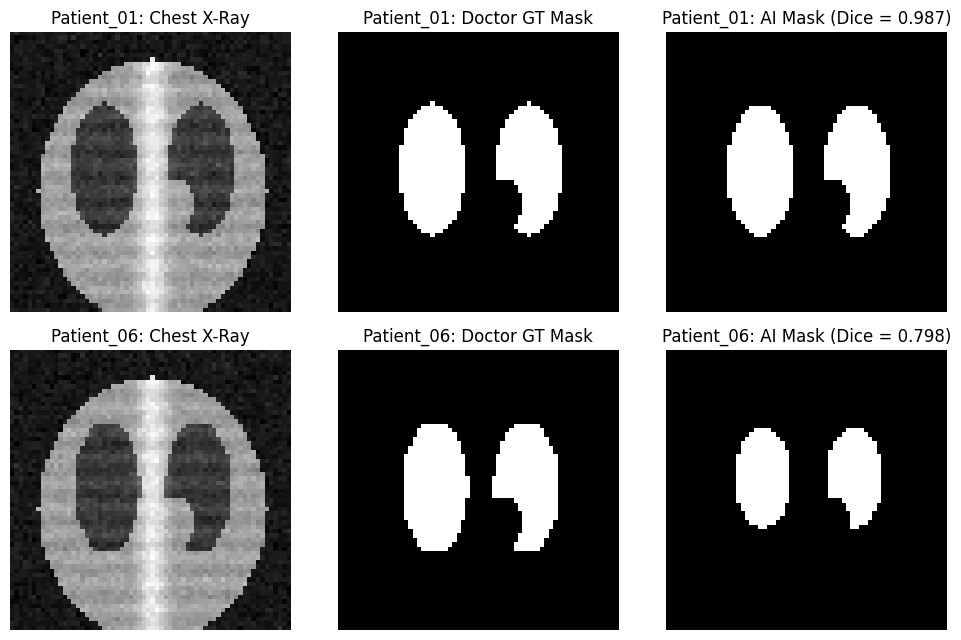

In [22]:
plt.figure(figsize=(10, 6.5))

for row_i, pat_idx in enumerate([0, 5]):  # Patient_01 (idx 0) vs Patient_06 (idx 5)
    pid = patient_ids[pat_idx]
    dice_val = compute_dice(gt_masks[pat_idx], ai_masks[pat_idx])

    # Column 1: Input Chest X-Ray
    plt.subplot(2, 3, row_i * 3 + 1)
    plt.imshow(xrays[pat_idx], cmap="gray")
    plt.title(f"{pid}: Chest X-Ray")
    plt.axis("off")

    # Column 2: Doctor's Ground-Truth Mask
    plt.subplot(2, 3, row_i * 3 + 2)
    plt.imshow(gt_masks[pat_idx], cmap="gray")
    plt.title(f"{pid}: Doctor GT Mask")
    plt.axis("off")

    # Column 3: AI Segmentation Mask + Quantitative Score in Title
    plt.subplot(2, 3, row_i * 3 + 3)
    plt.imshow(ai_masks[pat_idx], cmap="gray")
    plt.title(f"{pid}: AI Mask (Dice = {dice_val:.3f})")
    plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#0E7490"><b>Worked example 2: Draw Doctor (Green) vs. AI (Red) Boundary Outlines on the X-Ray (<code>plt.contour</code>)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When you color in an entire mask on top of an X-ray, the solid paint can cover up subtle details inside the lung. Radiologists love <b>Contour Overlays</b> (created with <b><code>plt.contour(mask, levels=[0.5], colors=...)</code></b>), which trace only the <b>outer border wall</b> of the mask:</font></p>
<ul>
  <li><font color="#177345"><b>Green Line (<code>colors="lime"</code>):</b></font> <font color="#334155">The Doctor's true lung boundary.</font></li>
  <li><font color="#DC2626"><b>Red Dashed Line (<code>colors="red", linestyles="dashed"</code>):</b></font> <font color="#334155">The AI's predicted lung boundary.</font></li>
</ul>
<p><font color="#334155">Where the red dashed line sits right on top of the green line, the AI boundary is exact! Try running the cell below to compare the boundary contours across <code>Patient_01</code> (Excellent), <code>Patient_05</code> (Over-segmented), and <code>Patient_06</code> (Under-segmented).</font></p>


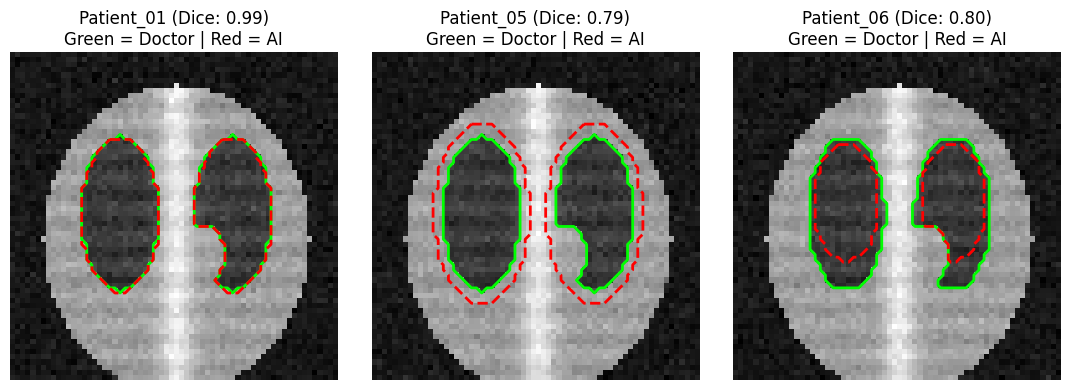

In [23]:
plt.figure(figsize=(11, 3.8))

for plot_i, pat_idx in enumerate([0, 4, 5]):
    pid = patient_ids[pat_idx]
    d_val = compute_dice(gt_masks[pat_idx], ai_masks[pat_idx])

    plt.subplot(1, 3, plot_i + 1)
    plt.imshow(xrays[pat_idx], cmap="gray")
    # Draw Doctor's Ground-Truth border in solid bright Green
    plt.contour(gt_masks[pat_idx], levels=[0.5], colors="lime", linewidths=2.0)
    # Draw AI's Predicted border in dashed Red
    plt.contour(ai_masks[pat_idx], levels=[0.5], colors="red", linewidths=2.0, linestyles="dashed")
    plt.title(f"{pid} (Dice: {d_val:.2f})\nGreen = Doctor | Red = AI")
    plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 4.1 and work toward Exercise 4.5.</font> <font color="#334155">Practice creating qualitative side-by-side figures, transparent overlays, and contour plots.</font></p>

<p><font color="#7135B5"><b>Exercise 4.1 — Display <code>Patient_02</code>'s X-Ray, Doctor GT Mask, and AI Mask side by side</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>Patient_02</code> (`index 1`), create a 1×3 subplot showing <code>xrays[1]</code>, <code>gt_masks[1]</code>, and <code>ai_masks[1]</code> in grayscale, and call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 3-panel row showing Patient 02's X-ray, true lung mask, and AI lung mask.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Use <code>plt.subplot(1, 3, 1)</code>, <code>(1, 3, 2)</code>, and <code>(1, 3, 3)</code> with <code>plt.imshow(..., cmap="gray")</code> on index <code>1</code>.</font></p>


In [24]:
# Exercise 4.1 — Display Patient_02's X-Ray, Doctor GT Mask, and AI Mask side by side
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.2 — Overlay the AI Mask onto <code>Patient_03</code>'s X-Ray using <code>alpha=0.4</code></b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Display <code>xrays[2]</code> with <code>cmap="gray"</code>, then call <code>plt.imshow(ai_masks[2], cmap="cool", alpha=0.4)</code> right underneath it so the AI mask appears as a semi-transparent color overlay, and call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Patient 03's X-ray with a translucent cyan/magenta highlight over the predicted lungs.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Call <code>plt.imshow(xrays[2], cmap="gray")</code>, then <code>plt.imshow(ai_masks[2], cmap="cool", alpha=0.4)</code>, and <code>plt.show()</code>.</font></p>


In [25]:
# Exercise 4.2 — Overlay the AI Mask onto Patient_03's X-Ray using alpha=0.4
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.3 — Draw a Green Contour Outline of the Doctor's Mask on <code>Patient_04</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Display <code>xrays[3]</code> in grayscale, and draw the outline of <code>gt_masks[3]</code> on top using <code>plt.contour(gt_masks[3], levels=[0.5], colors="lime", linewidths=2)</code>. Call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Patient 04's X-ray with bright green outline curves tracing the left and right lungs.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. <code>plt.imshow(xrays[3], cmap="gray")</code> &nbsp; 2. <code>plt.contour(gt_masks[3], levels=[0.5], colors="lime", linewidths=2)</code> &nbsp; 3. <code>plt.show()</code>.</font></p>


In [26]:
# Exercise 4.3 — Draw a Green Contour Outline of the Doctor's Mask on Patient_04
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.4 — Compare Doctor (Green) and AI (Red) Contours on <code>Patient_03</code> (`index 2`)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Display <code>xrays[2]</code> in grayscale, add the Doctor's contour <code>gt_masks[2]</code> in <code>colors="lime"</code>, and add the AI's contour <code>ai_masks[2]</code> in <code>colors="red"</code> with <code>linestyles="dashed"</code>. Include the patient's Dice score in the plot title!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A single X-ray image with both green and dashed-red outlines hugging the lung borders.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Follow Worked Example 2 for a single index <code>pat_idx = 2</code>.</font></p>


In [27]:
# Exercise 4.4 — Compare Doctor (Green) and AI (Red) Contours on Patient_03 (index 2)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.5 — Crop and Zoom In on the Left Lung Contour of <code>Patient_06</code> to Inspect the Missed Corner</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> In Module 3, you learned how to crop a 2D array using slicing! Slice out the right side of the image (Rows `12:54`, Columns `32:58`) for <code>xrays[5]</code>, <code>gt_masks[5]</code>, and <code>ai_masks[5]</code>. Display the cropped X-ray and plot both the Green (`gt`) and Red (`ai`) contours on the zoomed-in crop so you can clearly see the gap at the bottom of the lung!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A zoomed-in view of one lung where the red AI contour stops short of the bottom green Doctor contour.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Slice <code>crop_x = xrays[5][12:54, 32:58]</code>, <code>crop_gt = gt_masks[5][12:54, 32:58]</code>, and <code>crop_ai = ai_masks[5][12:54, 32:58]</code>. &nbsp; 2. Call <code>plt.imshow(crop_x, cmap="gray")</code> and add both <code>plt.contour(...)</code> calls on <code>crop_gt</code> and <code>crop_ai</code>.</font></p>


In [28]:
# Exercise 4.5 — Crop and Zoom In on the Left Lung Contour of Patient_06
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>5. Qualitative Analysis II: Color-Coded TP / FP / FN Diagnostic Error Maps</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Lesson 1, we counted the four pixel outcomes (<code>TP</code>, <code>FP</code>, <code>FN</code>, <code>TN</code>). In Lesson 4, we looked at grayscale masks side by side. What if we combine both ideas into a single <b>Color-Coded RGB Diagnostic Map</b> where each outcome gets its own unmistakable color?</font></p>

<p><font color="#334155">Remember from our Bonus Lab in Module 3 that a color image has shape <b><code>(Rows, Columns, 3)</code></b> where Channel 0 is <b>Red</b>, Channel 1 is <b>Green</b>, and Channel 2 is <b>Blue</b>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Pixel Outcome</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Color on Map</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>RGB Channel Values <code>[R, G, B]</code></b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Tells the Viewer Instantly</b></font></th>
</tr>
<tr style="background:#f0fdf4">
  <td style="padding:7px"><b>True Positive (TP)</b><br><code>(gt == 1) &amp; (ai == 1)</code></td>
  <td style="padding:7px"><font color="#177345"><b>Bright Green</b></font></td>
  <td style="padding:7px"><code>[0.0, 0.85, 0.2]</code></td>
  <td style="padding:7px"><b>Agreement:</b> AI correctly segmented the organ here!</td>
</tr>
<tr style="background:#fef2f2">
  <td style="padding:7px"><b>False Positive (FP)</b><br><code>(gt == 0) &amp; (ai == 1)</code></td>
  <td style="padding:7px"><font color="#DC2626"><b>Bright Red</b></font></td>
  <td style="padding:7px"><code>[0.95, 0.15, 0.15]</code></td>
  <td style="padding:7px"><b>Over-segmentation Spill:</b> AI painted outside the true organ border!</td>
</tr>
<tr style="background:#eff6ff">
  <td style="padding:7px"><b>False Negative (FN)</b><br><code>(gt == 1) &amp; (ai == 0)</code></td>
  <td style="padding:7px"><font color="#2563EB"><b>Bright Blue</b></font></td>
  <td style="padding:7px"><code>[0.15, 0.45, 1.0]</code></td>
  <td style="padding:7px"><b>Under-segmentation Miss:</b> AI missed this part of the true organ!</td>
</tr>
<tr>
  <td style="padding:7px"><b>True Negative (TN)</b><br><code>(gt == 0) &amp; (ai == 0)</code></td>
  <td style="padding:7px"><b>Black</b></td>
  <td style="padding:7px"><code>[0.0, 0.0, 0.0]</code></td>
  <td style="padding:7px"><b>Background:</b> Stays dark so the colors pop out clearly.</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: Build a Reusable <code>make_color_error_map(gt, ai)</code> Function</b></font></h3>
<p><font color="#334155">Let's write a clean helper function that takes any 2D `gt` mask and `ai` mask and returns a `(64, 64, 3)` color-coded RGB image. We will test it across three classic cases: <b><code>Patient_01</code> (Excellent)</b>, <b><code>Patient_05</code> (Over-segmented)</b>, and <b><code>Patient_06</code> (Under-segmented)</b>!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell and see how the <b>Red halo</b> on <code>Patient_05</code> and the <b>Blue missing bases</b> on <code>Patient_06</code> jump right off the screen!</p>


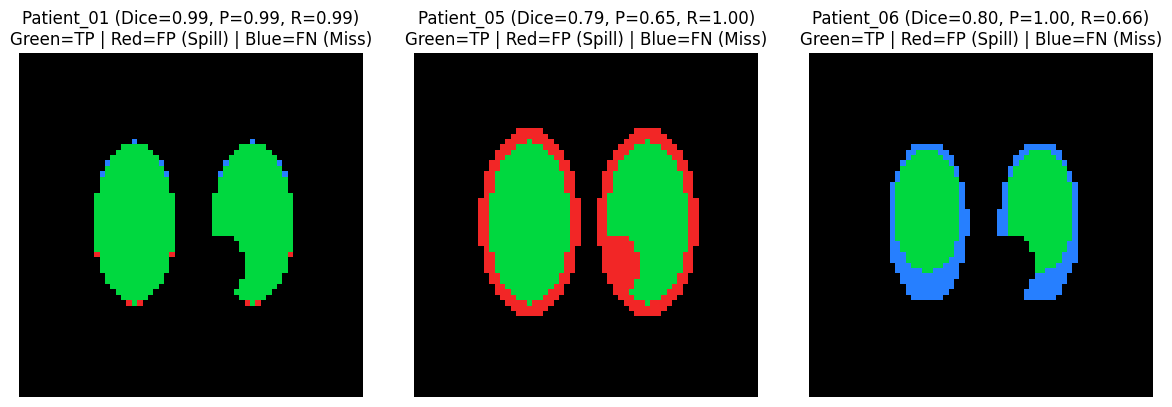

In [29]:
def make_color_error_map(gt, ai):
    """
    Creates an RGB image (H, W, 3) color-coding every pixel outcome:
      - Green = True Positive  (TP: Hit)
      - Red   = False Positive (FP: Over-segmentation spill)
      - Blue  = False Negative (FN: Under-segmentation miss)
      - Black = True Negative  (TN: Background)
    """
    h, w = gt.shape
    rgb_map = np.zeros((h, w, 3), dtype=np.float32)

    tp_mask = (gt == 1) & (ai == 1)
    fp_mask = (gt == 0) & (ai == 1)
    fn_mask = (gt == 1) & (ai == 0)

    rgb_map[tp_mask] = [0.0, 0.85, 0.25]   # Green = TP
    rgb_map[fp_mask] = [0.95, 0.15, 0.15]  # Red   = FP (Spill)
    rgb_map[fn_mask] = [0.15, 0.50, 1.00]  # Blue  = FN (Miss)

    return rgb_map

plt.figure(figsize=(12, 4))

for plot_i, pat_idx in enumerate([0, 4, 5]):
    pid = patient_ids[pat_idx]
    gt_i, ai_i = gt_masks[pat_idx], ai_masks[pat_idx]
    color_map = make_color_error_map(gt_i, ai_i)
    d = compute_dice(gt_i, ai_i)
    p = compute_precision(gt_i, ai_i)
    r = compute_recall(gt_i, ai_i)

    plt.subplot(1, 3, plot_i + 1)
    plt.imshow(color_map)
    plt.title(f"{pid} (Dice={d:.2f}, P={p:.2f}, R={r:.2f})\nGreen=TP | Red=FP (Spill) | Blue=FN (Miss)")
    plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#0E7490"><b>Worked example 2: Blend the Color Diagnostic Map Directly Over the Grayscale Chest X-Ray</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">What if we want to see the <b>Green (TP)</b>, <b>Red (FP)</b>, and <b>Blue (FN)</b> regions <i>while still seeing the ribs, heart, and spine in the grayscale X-ray underneath</i>? We can stack the 2D grayscale X-ray into a 3-channel RGB background (`np.stack([xray, xray, xray], axis=-1)`) and blend the color error map on top wherever the mask is active!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to generate a 4-panel Qualitative Diagnostic Row for <code>Patient_03</code> (**X-Ray | Doctor GT | AI Mask | Blended Color Diagnostic Overlay**).</p>


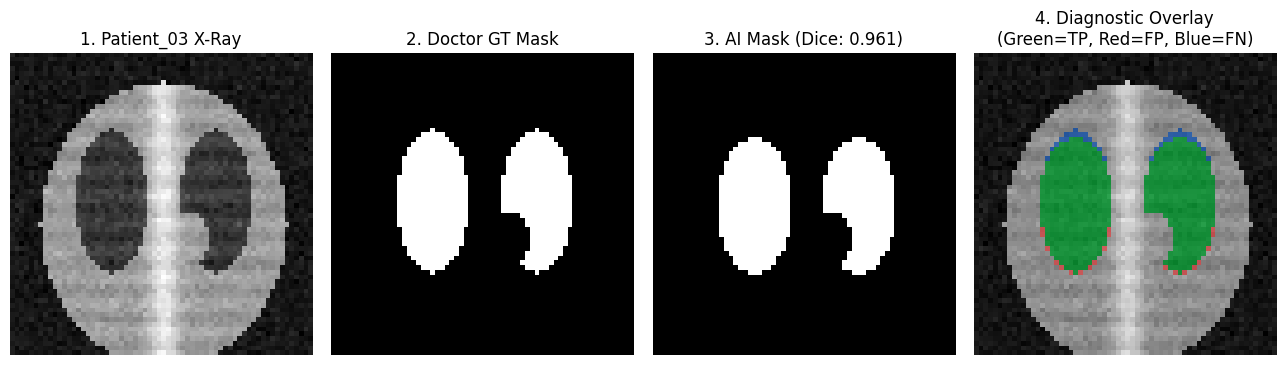

In [30]:
def make_blended_xray_overlay(xray, gt, ai, alpha=0.55):
    """Blends the Green/Red/Blue diagnostic map onto the grayscale X-ray background."""
    # Convert 2D grayscale X-ray (H, W) into a 3-channel grayscale RGB image (H, W, 3)
    xray_rgb = np.stack([xray, xray, xray], axis=-1)
    color_map = make_color_error_map(gt, ai)

    # Blend color only on pixels that are TP, FP, or FN (leave background TN as pure X-ray!)
    active_pixels = (gt == 1) | (ai == 1)
    blended = xray_rgb.copy()
    blended[active_pixels] = (1.0 - alpha) * xray_rgb[active_pixels] + alpha * color_map[active_pixels]
    return np.clip(blended, 0.0, 1.0)

pat_idx = 2  # Patient_03
overlay_img = make_blended_xray_overlay(xrays[pat_idx], gt_masks[pat_idx], ai_masks[pat_idx])

plt.figure(figsize=(13, 3.5))

plt.subplot(1, 4, 1)
plt.imshow(xrays[pat_idx], cmap="gray")
plt.title(f"1. {patient_ids[pat_idx]} X-Ray")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_masks[pat_idx], cmap="gray")
plt.title("2. Doctor GT Mask")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(ai_masks[pat_idx], cmap="gray")
plt.title(f"3. AI Mask (Dice: {compute_dice(gt_masks[pat_idx], ai_masks[pat_idx]):.3f})")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(overlay_img)
plt.title("4. Diagnostic Overlay\n(Green=TP, Red=FP, Blue=FN)")
plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 5.1 and work toward Exercise 5.5.</font> <font color="#334155">Practice building and interpreting color-coded diagnostic error maps.</font></p>

<p><font color="#7135B5"><b>Exercise 5.1 — Check the 3D shape of a Color Error Map</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Call <code>cmap_0 = make_color_error_map(gt_masks[0], ai_masks[0])</code> for <code>Patient_01</code> and print <code>cmap_0.shape</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Even though `gt_masks[0]` and `ai_masks[0]` are 2D `(64, 64)` grids, the color diagnostic map has 3 RGB channels `(64, 64, 3)` so it can paint Green, Red, and Blue!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>(64, 64, 3)</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>cmap_0 = make_color_error_map(gt_masks[0], ai_masks[0])</code> and <code>print(cmap_0.shape)</code>.</font></p>


In [31]:
# Exercise 5.1 — Check the 3D shape of a Color Error Map
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.2 — Display the Color Error Map for <code>Patient_02</code> (`index 1`)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Generate <code>cmap_1 = make_color_error_map(gt_masks[1], ai_masks[1])</code> and display it with <code>plt.imshow(cmap_1)</code> and a descriptive title.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A black background with two bright green lungs and only a few tiny red/blue border pixels.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>cmap_1</code>, call <code>plt.imshow(cmap_1)</code>, add <code>plt.title(...)</code>, and call <code>plt.show()</code>.</font></p>


In [32]:
# Exercise 5.2 — Display the Color Error Map for Patient_02 (index 1)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.3 — Display the Blended X-Ray Diagnostic Overlay for <code>Patient_04</code> (`index 3`)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>make_blended_xray_overlay(xrays[3], gt_masks[3], ai_masks[3])</code> to create the blended diagnostic image for <code>Patient_04</code> and display it with <code>plt.imshow(...)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Patient 04's X-ray with the green/red/blue diagnostic map blended over the lung fields.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Call <code>blend_3 = make_blended_xray_overlay(xrays[3], gt_masks[3], ai_masks[3])</code>, then <code>plt.imshow(blend_3)</code> and <code>plt.show()</code>.</font></p>


In [33]:
# Exercise 5.3 — Display the Blended X-Ray Diagnostic Overlay for Patient_04 (index 3)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.4 — Compare Over-Segmentation (`Patient_05`) vs. Under-Segmentation (`Patient_06`) using Blended Overlays Side by Side</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>plt.subplot(1, 2, 1)</code> to show the blended X-ray overlay for <code>Patient_05</code> (`index 4`) and <code>plt.subplot(1, 2, 2)</code> to show the blended X-ray overlay for <code>Patient_06</code> (`index 5`).</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Side by side on the real X-ray anatomy, you can immediately see how `Patient_05` spills in **Red** over the ribs and heart, while `Patient_06` leaves the lower lung bases painted **Blue**!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Two side-by-side blended X-ray overlays contrasting the Red spill halo vs. the Blue missed lung bases.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Call <code>make_blended_xray_overlay(...)</code> for index `4` and index `5` and plot them in a `1×2` subplot.</font></p>


In [34]:
# Exercise 5.4 — Compare Over-Segmentation vs. Under-Segmentation using Blended Overlays
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.5 — Build a Custom Binary Disagreement Map (Highlighting ONLY Errors FP + FN in White)</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Sometimes you want to isolate <i>only</i> the mistake pixels (both False Positives AND False Negatives) as a binary `0`/`1` grid. For <code>Patient_03</code> (`index 2`), compute <code>mistakes = (gt_masks[2] != ai_masks[2]).astype(int)</code>, print the total number of mistake pixels (<code>mistakes.sum()</code>), and verify that it equals <code>FP + FN</code>!</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In Python, `!=` means **"not equal to"**. Wherever `gt != ai`, the AI either spilled (`0 != 1`) or missed (`1 != 0`), so `(gt != ai).sum()` is always `FP + FN`!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>91</code> on line 1, and <code>True</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>mistakes = (gt_masks[2] != ai_masks[2]).astype(int)</code> and print <code>mistakes.sum()</code>. &nbsp; 2. Compute <code>fp_plus_fn = np.sum((gt_masks[2]==0)&amp;(ai_masks[2]==1)) + np.sum((gt_masks[2]==1)&amp;(ai_masks[2]==0))</code> and print <code>mistakes.sum() == fp_plus_fn</code>.</font></p>


In [35]:
# Exercise 5.5 — Build a Custom Binary Disagreement Map (Highlighting ONLY Errors FP + FN)
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>6. Putting It All Together: Quantitative Cohort Charts &amp; Best-vs-Worst Qualitative Figures</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When you present your medical segmentation project at the KSU iCARE Lab Symposium, judges will look for two things on your poster:</font></p>
<ol>
  <li><font color="#0E7490"><b>A Quantitative Summary (Mean ± Standard Deviation + Bar Chart):</b></font> <font color="#334155">Across all test patients, what was the <b>average (`.mean()`)</b> Dice and IoU score, and how much did it vary from patient to patient (<b>standard deviation `.std()`</b>)? Which patients scored above or below the average line?</font></li>
  <li><font color="#177345"><b>A Qualitative Best-Case vs. Worst-Case Visual Figure:</b></font> <font color="#334155">Instead of cherry-picking only your best image, honest scientific reporting shows the <b>Best Patient (`np.argmax(dice_scores)`)</b> right above the <b>Hardest / Worst Patient (`np.argmin(dice_scores)`)</b> along with their color-coded error maps!</font></li>
</ol>

<h3><font color="#0E7490"><b>Worked example 1: Compute Cohort Mean ± Std and Plot a Patient-by-Patient Quantitative Bar Chart</b></font></h3>
<p><font color="#334155">Let's collect the Dice, IoU, Precision, and Recall scores across all 6 patients into NumPy arrays, print the official <b>Mean ± Std</b> research summary, and draw a bar chart with a horizontal dashed line showing the cohort average!</font></p>


=== KSU iCARE Lab Quantitative Evaluation Summary (n = 6 Patients) ===
Dice Similarity Score : 0.910 ± 0.084 (Min: 0.787, Max: 0.987)
IoU (Jaccard Index)   : 0.846 ± 0.136
Precision             : 0.922 ± 0.123
Recall (Sensitivity)  : 0.923 ± 0.117


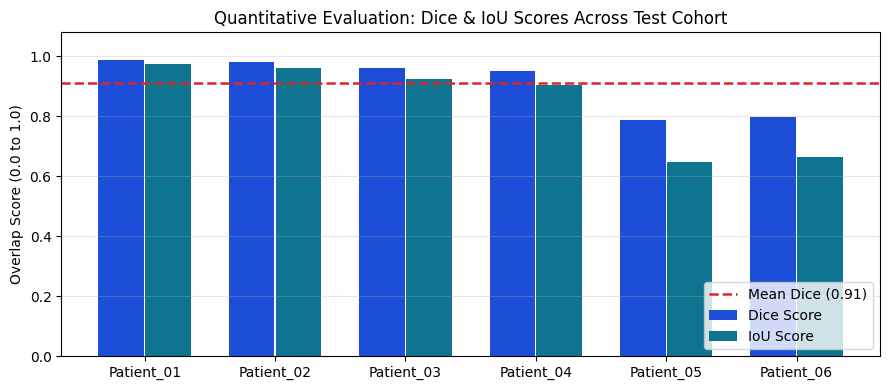

In [36]:
# Collect quantitative metrics across all 6 patients into NumPy arrays
cohort_dice = np.array([compute_dice(gt_masks[i], ai_masks[i]) for i in range(len(patient_ids))])
cohort_iou  = np.array([compute_iou(gt_masks[i], ai_masks[i])  for i in range(len(patient_ids))])
cohort_prec = np.array([compute_precision(gt_masks[i], ai_masks[i]) for i in range(len(patient_ids))])
cohort_rec  = np.array([compute_recall(gt_masks[i], ai_masks[i])    for i in range(len(patient_ids))])

print("=== KSU iCARE Lab Quantitative Evaluation Summary (n = 6 Patients) ===")
print(f"Dice Similarity Score : {cohort_dice.mean():.3f} ± {cohort_dice.std():.3f} (Min: {cohort_dice.min():.3f}, Max: {cohort_dice.max():.3f})")
print(f"IoU (Jaccard Index)   : {cohort_iou.mean():.3f} ± {cohort_iou.std():.3f}")
print(f"Precision             : {cohort_prec.mean():.3f} ± {cohort_prec.std():.3f}")
print(f"Recall (Sensitivity)  : {cohort_rec.mean():.3f} ± {cohort_rec.std():.3f}")

# Plot a Quantitative Bar Chart of Dice & IoU by Patient
x_pos = np.arange(len(patient_ids))
plt.figure(figsize=(9, 4))
plt.bar(x_pos - 0.18, cohort_dice, width=0.35, label="Dice Score", color="#1D4ED8")
plt.bar(x_pos + 0.18, cohort_iou,  width=0.35, label="IoU Score",  color="#0E7490")

# Draw a horizontal dashed line for the Mean Dice Score
plt.axhline(cohort_dice.mean(), color="#DC2626", linestyle="--", linewidth=1.8,
            label=f"Mean Dice ({cohort_dice.mean():.2f})")

plt.xticks(x_pos, patient_ids)
plt.ylim(0.0, 1.08)
plt.ylabel("Overlap Score (0.0 to 1.0)")
plt.title("Quantitative Evaluation: Dice & IoU Scores Across Test Cohort")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


<h3><font color="#0E7490"><b>Worked example 2: Automatically Find the Best &amp; Worst Case (<code>np.argmax</code> / <code>np.argmin</code>) and Save a Combined Poster Figure</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In NumPy, <code>np.max(cohort_dice)</code> tells you the highest Dice score, while <b><code>np.argmax(cohort_dice)</code></b> tells you the <b>index position (which patient!)</b> achieved that highest score. Similarly, <b><code>np.argmin(cohort_dice)</code></b> finds the index of the lowest-scoring patient.</font></p>
<p><font color="#334155">Let's use `np.argmax()` and `np.argmin()` to automatically select the **Best Case** and **Worst Case** from our cohort, build a 2-row × 4-column **Quantitative + Qualitative Summary Figure**, and save it to your Google Drive folder!</font></p>


Best Case  -> Patient_01 (Index 0) with Dice = 0.9873
Worst Case -> Patient_05 (Index 4) with Dice = 0.7871


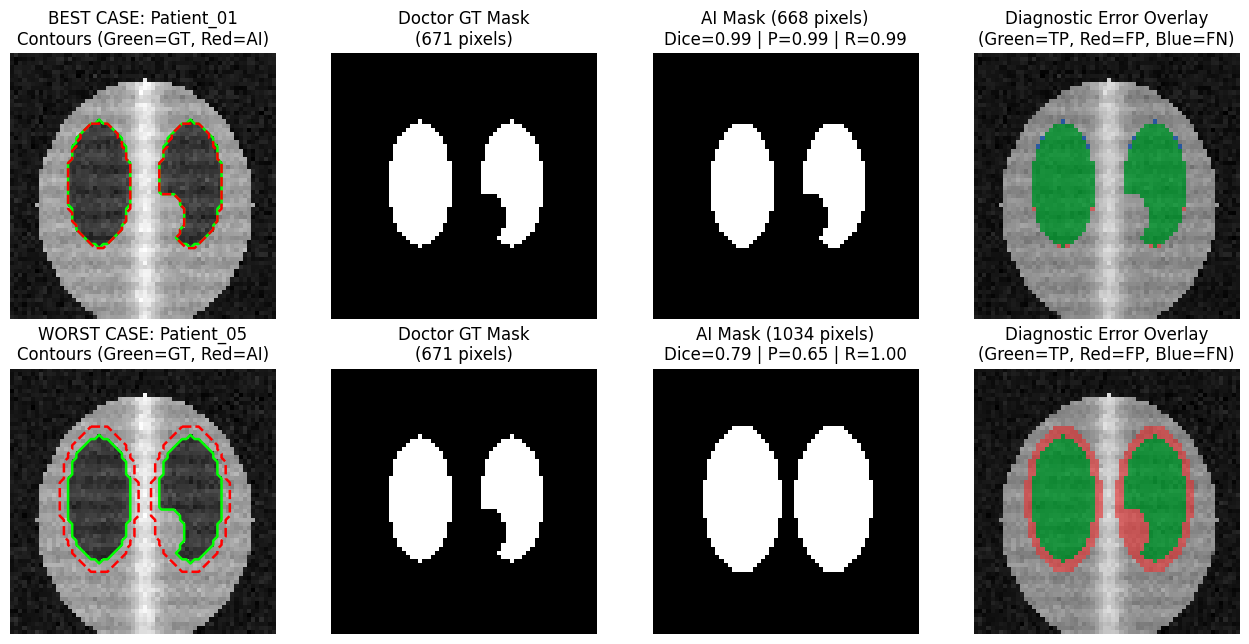

Saved high-resolution poster figure to Google Drive: /content/drive/MyDrive/KSU_iCARE_2D_Seg_Evaluation/best_vs_worst_evaluation_poster.png


In [37]:
best_idx  = int(np.argmax(cohort_dice))
worst_idx = int(np.argmin(cohort_dice))

print(f"Best Case  -> {patient_ids[best_idx]} (Index {best_idx}) with Dice = {cohort_dice[best_idx]:.4f}")
print(f"Worst Case -> {patient_ids[worst_idx]} (Index {worst_idx}) with Dice = {cohort_dice[worst_idx]:.4f}")

plt.figure(figsize=(13, 6.5))

for row_i, (label_tag, idx) in enumerate([("BEST CASE", best_idx), ("WORST CASE", worst_idx)]):
    pid = patient_ids[idx]
    xray_i, gt_i, ai_i = xrays[idx], gt_masks[idx], ai_masks[idx]
    d_i, p_i, r_i = cohort_dice[idx], cohort_prec[idx], cohort_rec[idx]

    # Column 1: Chest X-Ray with Green (GT) & Red (AI) Contours
    plt.subplot(2, 4, row_i * 4 + 1)
    plt.imshow(xray_i, cmap="gray")
    plt.contour(gt_i, levels=[0.5], colors="lime", linewidths=1.8)
    plt.contour(ai_i, levels=[0.5], colors="red", linewidths=1.8, linestyles="dashed")
    plt.title(f"{label_tag}: {pid}\nContours (Green=GT, Red=AI)")
    plt.axis("off")

    # Column 2: Doctor Ground-Truth Mask
    plt.subplot(2, 4, row_i * 4 + 2)
    plt.imshow(gt_i, cmap="gray")
    plt.title(f"Doctor GT Mask\n({np.sum(gt_i==1)} pixels)")
    plt.axis("off")

    # Column 3: AI Segmentation Mask + Quantitative Metrics
    plt.subplot(2, 4, row_i * 4 + 3)
    plt.imshow(ai_i, cmap="gray")
    plt.title(f"AI Mask ({np.sum(ai_i==1)} pixels)\nDice={d_i:.2f} | P={p_i:.2f} | R={r_i:.2f}")
    plt.axis("off")

    # Column 4: Blended Color Diagnostic Error Map
    plt.subplot(2, 4, row_i * 4 + 4)
    plt.imshow(make_blended_xray_overlay(xray_i, gt_i, ai_i))
    plt.title("Diagnostic Error Overlay\n(Green=TP, Red=FP, Blue=FN)")
    plt.axis("off")

plt.tight_layout()
poster_fig_path = os.path.join(EVAL_DIR, "best_vs_worst_evaluation_poster.png")
plt.savefig(poster_fig_path, dpi=150)
plt.show()
print("Saved high-resolution poster figure to Google Drive:", poster_fig_path)


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 6.1 and work toward Exercise 6.5.</font> <font color="#334155">Practice summarizing cohort metrics, finding best/worst cases, and exporting evaluation results.</font></p>

<p><font color="#7135B5"><b>Exercise 6.1 — Compute the Cohort Average and Standard Deviation of the Dice Score</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the <code>cohort_dice</code> array from Worked Example 1, print <code>round(float(cohort_dice.mean()), 3)</code> on line 1 and <code>round(float(cohort_dice.std()), 3)</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.903</code> on line 1, and <code>0.075</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(round(float(cohort_dice.mean()), 3))</code> and <code>print(round(float(cohort_dice.std()), 3))</code>.</font></p>


In [38]:
# Exercise 6.1 — Compute the Cohort Average and Standard Deviation of the Dice Score
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.2 — Use <code>np.argmax</code> and <code>np.argmin</code> to print the Best and Worst Patient IDs</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Find the index of the highest Dice score using <code>best_i = np.argmax(cohort_dice)</code> and the lowest Dice score using <code>worst_i = np.argmin(cohort_dice)</code>. Print <code>patient_ids[best_i]</code> on line 1 and <code>patient_ids[worst_i]</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>Patient_01</code> on line 1, and <code>Patient_05</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>best_i</code> and <code>worst_i</code>, then print <code>patient_ids[best_i]</code> and <code>patient_ids[worst_i]</code>.</font></p>


In [39]:
# Exercise 6.2 — Use np.argmax and np.argmin to print the Best and Worst Patient IDs
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.3 — Count how many patients achieved a Clinical-Grade Dice Score of at least <code>0.90</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> In lung segmentation, a Dice score of <code>0.90</code> or higher is often considered strong clinical agreement. Use boolean condition counting <code>np.sum(cohort_dice &gt;= 0.90)</code> to count how many of our 6 test patients achieved <code>&gt;= 0.90</code>, and print the count.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>4</code> (Patients 01, 02, 03, and 04!).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>high_performers = np.sum(cohort_dice &gt;= 0.90)</code> and <code>print(high_performers)</code>.</font></p>


In [40]:
# Exercise 6.3 — Count how many patients achieved a Clinical-Grade Dice Score of at least 0.90
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.4 — Plot a Bar Chart Comparing Precision vs. Recall Across All 6 Patients</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a grouped bar chart using <code>x_pos = np.arange(len(patient_ids))</code> where <code>plt.bar(x_pos - 0.18, cohort_prec, width=0.35, label="Precision")</code> and <code>plt.bar(x_pos + 0.18, cohort_rec, width=0.35, label="Recall")</code> are plotted side by side for each patient. Add <code>plt.xticks(x_pos, patient_ids)</code>, <code>plt.legend()</code>, and <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at the last two patients on this chart: on `Patient_05`, the Precision bar drops while Recall is 1.0; on `Patient_06`, the Recall bar drops while Precision is 1.0!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A grouped bar chart comparing Precision and Recall for all 6 patients.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Follow the bar chart pattern from Worked Example 1, replacing `cohort_dice` and `cohort_iou` with `cohort_prec` and `cohort_rec`.</font></p>


In [41]:
# Exercise 6.4 — Plot a Bar Chart Comparing Precision vs. Recall Across All 6 Patients
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.5 — Save a Quantitative CSV Evaluation Report Table to Google Drive</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Write a loop that saves all 6 patients' quantitative metrics (`Patient_ID,Dice,IoU,Precision,Recall`) into a comma-separated text file named <code>evaluation_metrics.csv</code> inside <code>EVAL_DIR</code> so you can open it in Excel or Google Sheets! Print <code>os.path.exists(csv_path)</code> and display the file contents.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>True</code> followed by the 6-row CSV table.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Open <code>csv_path = os.path.join(EVAL_DIR, "evaluation_metrics.csv")</code> with <code>open(csv_path, "w")</code>, write the header row and each patient row, then read and print the file.</font></p>


In [42]:
# Exercise 6.5 — Save a Quantitative CSV Evaluation Report Table to Google Drive
# Write your Python code below.


<hr>
<h1><font color="#177345"><b>Solutions — Check After You Try</b></font></h1>
<p><font color="#177345"><b>Complete solutions for Exercises 1.1 through 6.5 are provided below.</b></font> <font color="#334155">Run each code cell to verify your results.</font></p>


In [43]:
print("=== LESSON 1 SOLUTIONS (Pixel Outcomes: TP, FP, FN, TN) ===")

# Solution 1.1
gt = np.array([1, 1, 0, 1, 0])
ai = np.array([1, 0, 0, 1, 1])
tp = np.sum((gt == 1) & (ai == 1))
print("1.1 TP count ->", tp)

# Solution 1.2
gt_box = np.array([[1, 1], [1, 0]])
ai_box = np.array([[1, 0], [0, 1]])
fp = np.sum((gt_box == 0) & (ai_box == 1))
fn = np.sum((gt_box == 1) & (ai_box == 0))
print("1.2 FP:", fp, "| FN:", fn)

# Solution 1.3
print("1.3 TP + FN:", tp_0 + fn_0, "| Total Doctor Organ Pixels:", np.sum(gt_0 == 1))

# Solution 1.4
gt_4, ai_4 = gt_masks[4], ai_masks[4]
print("1.4 Patient_05 (Over-seg) -> FP:", np.sum((gt_4 == 0) & (ai_4 == 1)), "| FN:", np.sum((gt_4 == 1) & (ai_4 == 0)))

# Solution 1.5
gt_5, ai_5 = gt_masks[5], ai_masks[5]
print("1.5 Patient_06 (Under-seg) -> FP:", np.sum((gt_5 == 0) & (ai_5 == 1)), "| FN:", np.sum((gt_5 == 1) & (ai_5 == 0)))

print("\n=== LESSON 2 SOLUTIONS (Quantitative Overlap: Dice & IoU) ===")

# Solution 2.1
TP, FP, FN = 40, 10, 10
dice = (2.0 * TP) / (2.0 * TP + FP + FN)
print("2.1 Dice Score ->", round(dice, 2))

# Solution 2.2
iou = TP / (TP + FP + FN)
print("2.2 IoU Score ->", round(iou, 3))

# Solution 2.3
print("2.3 Self-match Dice:", round(compute_dice(gt_masks[0], gt_masks[0]), 2),
      "| Zero-mask Dice:", round(compute_dice(gt_masks[0], np.zeros_like(gt_masks[0])), 2))

# Solution 2.4
zero_ai = np.zeros_like(gt_masks[0])
pix_acc = round(float(np.mean(zero_ai == gt_masks[0])), 3)
zero_dice = round(compute_dice(gt_masks[0], zero_ai), 3)
print("2.4 All-Zero Prediction -> Plain Pixel Accuracy:", pix_acc, "| Dice Score:", zero_dice)

# Solution 2.5
iou_2 = compute_iou(gt_masks[2], ai_masks[2])
dice_from_iou = (2.0 * iou_2) / (1.0 + iou_2)
print("2.5 Dice from IoU formula:", round(dice_from_iou, 4), "| Direct Dice:", round(compute_dice(gt_masks[2], ai_masks[2]), 4))

print("\n=== LESSON 3 SOLUTIONS (Precision, Recall, & Area Error) ===")

# Solution 3.1
TP, FP = 80, 20
print("3.1 Precision ->", round(TP / (TP + FP), 2))

# Solution 3.2
TP, FN = 75, 25
print("3.2 Recall ->", round(TP / (TP + FN), 2))

# Solution 3.3
P = compute_precision(gt_masks[2], ai_masks[2])
R = compute_recall(gt_masks[2], ai_masks[2])
harmonic = (2.0 * P * R) / (P + R)
print("3.3 Harmonic Mean of P & R:", round(harmonic, 4), "| Direct Dice:", round(compute_dice(gt_masks[2], ai_masks[2]), 4))

# Solution 3.4
err_0 = abs(compute_area_error_pct(gt_masks[0], ai_masks[0]))
print("3.4 Patient_01 Absolute Area Error (%) ->", round(err_0, 2))

# Solution 3.5
print("3.5 Automated Diagnostic Labels:")
for i in range(6):
    p_i = compute_precision(gt_masks[i], ai_masks[i])
    r_i = compute_recall(gt_masks[i], ai_masks[i])
    if p_i < 0.80:
        tag = "Over-segmented"
    elif r_i < 0.80:
        tag = "Under-segmented"
    else:
        tag = "Balanced"
    print(f"   {patient_ids[i]}: {tag}")


=== LESSON 1 SOLUTIONS (Pixel Outcomes: TP, FP, FN, TN) ===
1.1 TP count -> 2
1.2 FP: 1 | FN: 2
1.3 TP + FN: 671 | Total Doctor Organ Pixels: 671
1.4 Patient_05 (Over-seg) -> FP: 363 | FN: 0
1.5 Patient_06 (Under-seg) -> FP: 0 | FN: 220

=== LESSON 2 SOLUTIONS (Quantitative Overlap: Dice & IoU) ===
2.1 Dice Score -> 0.8
2.2 IoU Score -> 0.667
2.3 Self-match Dice: 1.0 | Zero-mask Dice: 0.0
2.4 All-Zero Prediction -> Plain Pixel Accuracy: 0.836 | Dice Score: 0.0
2.5 Dice from IoU formula: 0.9609 | Direct Dice: 0.9609

=== LESSON 3 SOLUTIONS (Precision, Recall, & Area Error) ===
3.1 Precision -> 0.8
3.2 Recall -> 0.75
3.3 Harmonic Mean of P & R: 0.9609 | Direct Dice: 0.9609
3.4 Patient_01 Absolute Area Error (%) -> 0.45
3.5 Automated Diagnostic Labels:
   Patient_01: Balanced
   Patient_02: Balanced
   Patient_03: Balanced
   Patient_04: Balanced
   Patient_05: Over-segmented
   Patient_06: Under-segmented


=== LESSON 4 SOLUTIONS (Qualitative Visuals & Contours) ===


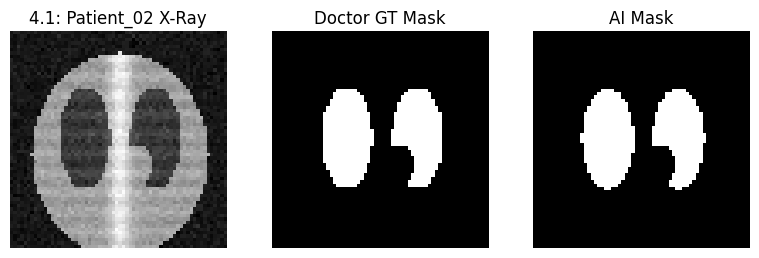

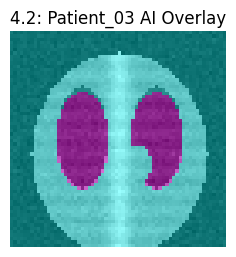

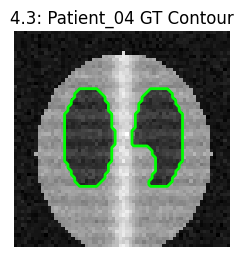

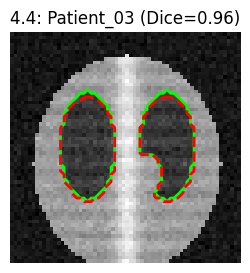

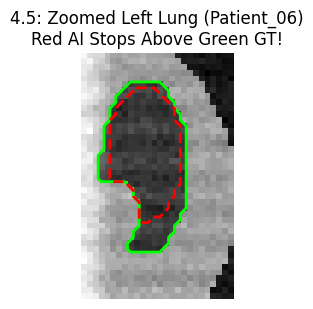


=== LESSON 5 SOLUTIONS (Color-Coded Diagnostic Error Maps) ===
5.1 Color Error Map shape -> (64, 64, 3)


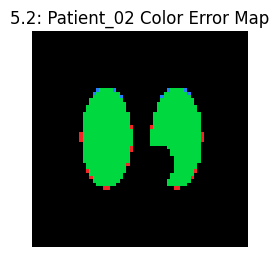

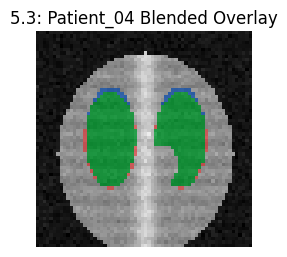

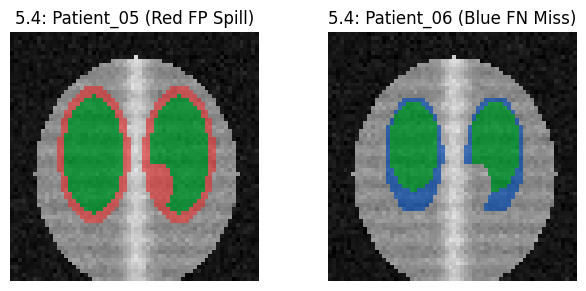

5.5 Mistake pixels (gt != ai): 52 | Equals FP + FN? -> True

=== LESSON 6 SOLUTIONS (Cohort Summary & Poster Exports) ===
6.1 Cohort Mean Dice: 0.91 | Std: 0.084
6.2 Best Patient: Patient_01 | Worst Patient: Patient_05
6.3 Patients with Dice >= 0.90 -> 4


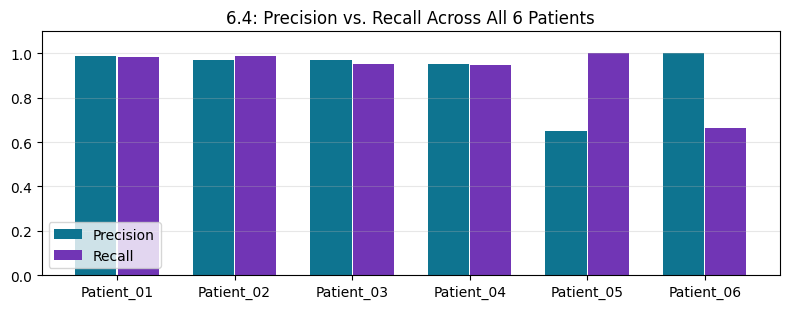

6.5 Saved CSV exists in Drive -> True
Patient_ID,Dice,IoU,Precision,Recall
Patient_01,0.9873,0.9749,0.9895,0.9851
Patient_02,0.9795,0.9599,0.9714,0.9878
Patient_03,0.9609,0.9247,0.9697,0.9523
Patient_04,0.9495,0.9038,0.9509,0.9480
Patient_05,0.7871,0.6489,0.6489,1.0000
Patient_06,0.7978,0.6636,1.0000,0.6636



In [44]:
print("=== LESSON 4 SOLUTIONS (Qualitative Visuals & Contours) ===")

# Solution 4.1
plt.figure(figsize=(8, 2.6))
plt.subplot(1, 3, 1); plt.imshow(xrays[1], cmap="gray"); plt.title("4.1: Patient_02 X-Ray"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(gt_masks[1], cmap="gray"); plt.title("Doctor GT Mask"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(ai_masks[1], cmap="gray"); plt.title("AI Mask"); plt.axis("off")
plt.tight_layout(); plt.show()

# Solution 4.2
plt.figure(figsize=(3, 2.8))
plt.imshow(xrays[2], cmap="gray")
plt.imshow(ai_masks[2], cmap="cool", alpha=0.4)
plt.title("4.2: Patient_03 AI Overlay")
plt.axis("off"); plt.show()

# Solution 4.3
plt.figure(figsize=(3, 2.8))
plt.imshow(xrays[3], cmap="gray")
plt.contour(gt_masks[3], levels=[0.5], colors="lime", linewidths=2)
plt.title("4.3: Patient_04 GT Contour")
plt.axis("off"); plt.show()

# Solution 4.4
plt.figure(figsize=(3.4, 3))
plt.imshow(xrays[2], cmap="gray")
plt.contour(gt_masks[2], levels=[0.5], colors="lime", linewidths=2)
plt.contour(ai_masks[2], levels=[0.5], colors="red", linewidths=2, linestyles="dashed")
plt.title(f"4.4: Patient_03 (Dice={compute_dice(gt_masks[2], ai_masks[2]):.2f})")
plt.axis("off"); plt.show()

# Solution 4.5
crop_x  = xrays[5][12:54, 32:58]
crop_gt = gt_masks[5][12:54, 32:58]
crop_ai = ai_masks[5][12:54, 32:58]
plt.figure(figsize=(3.2, 3.2))
plt.imshow(crop_x, cmap="gray")
plt.contour(crop_gt, levels=[0.5], colors="lime", linewidths=2)
plt.contour(crop_ai, levels=[0.5], colors="red", linewidths=2, linestyles="dashed")
plt.title("4.5: Zoomed Left Lung (Patient_06)\nRed AI Stops Above Green GT!")
plt.axis("off"); plt.show()

print("\n=== LESSON 5 SOLUTIONS (Color-Coded Diagnostic Error Maps) ===")

# Solution 5.1
cmap_0 = make_color_error_map(gt_masks[0], ai_masks[0])
print("5.1 Color Error Map shape ->", cmap_0.shape)

# Solution 5.2
cmap_1 = make_color_error_map(gt_masks[1], ai_masks[1])
plt.figure(figsize=(3, 2.8))
plt.imshow(cmap_1)
plt.title("5.2: Patient_02 Color Error Map")
plt.axis("off"); plt.show()

# Solution 5.3
blend_3 = make_blended_xray_overlay(xrays[3], gt_masks[3], ai_masks[3])
plt.figure(figsize=(3, 2.8))
plt.imshow(blend_3)
plt.title("5.3: Patient_04 Blended Overlay")
plt.axis("off"); plt.show()

# Solution 5.4
plt.figure(figsize=(6.5, 3))
plt.subplot(1, 2, 1)
plt.imshow(make_blended_xray_overlay(xrays[4], gt_masks[4], ai_masks[4]))
plt.title("5.4: Patient_05 (Red FP Spill)")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(make_blended_xray_overlay(xrays[5], gt_masks[5], ai_masks[5]))
plt.title("5.4: Patient_06 (Blue FN Miss)")
plt.axis("off")
plt.tight_layout(); plt.show()

# Solution 5.5
mistakes = (gt_masks[2] != ai_masks[2]).astype(int)
fp_plus_fn = np.sum((gt_masks[2] == 0) & (ai_masks[2] == 1)) + np.sum((gt_masks[2] == 1) & (ai_masks[2] == 0))
print("5.5 Mistake pixels (gt != ai):", mistakes.sum(), "| Equals FP + FN? ->", mistakes.sum() == fp_plus_fn)

print("\n=== LESSON 6 SOLUTIONS (Cohort Summary & Poster Exports) ===")

# Solution 6.1
print("6.1 Cohort Mean Dice:", round(float(cohort_dice.mean()), 3), "| Std:", round(float(cohort_dice.std()), 3))

# Solution 6.2
best_i  = int(np.argmax(cohort_dice))
worst_i = int(np.argmin(cohort_dice))
print("6.2 Best Patient:", patient_ids[best_i], "| Worst Patient:", patient_ids[worst_i])

# Solution 6.3
high_performers = int(np.sum(cohort_dice >= 0.90))
print("6.3 Patients with Dice >= 0.90 ->", high_performers)

# Solution 6.4
x_pos = np.arange(len(patient_ids))
plt.figure(figsize=(8, 3.2))
plt.bar(x_pos - 0.18, cohort_prec, width=0.35, label="Precision", color="#0E7490")
plt.bar(x_pos + 0.18, cohort_rec,  width=0.35, label="Recall",    color="#7135B5")
plt.xticks(x_pos, patient_ids)
plt.ylim(0.0, 1.1)
plt.title("6.4: Precision vs. Recall Across All 6 Patients")
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# Solution 6.5
csv_path = os.path.join(EVAL_DIR, "evaluation_metrics.csv")
with open(csv_path, "w") as f:
    f.write("Patient_ID,Dice,IoU,Precision,Recall\n")
    for i, pid in enumerate(patient_ids):
        f.write(f"{pid},{cohort_dice[i]:.4f},{cohort_iou[i]:.4f},{cohort_prec[i]:.4f},{cohort_rec[i]:.4f}\n")

print("6.5 Saved CSV exists in Drive ->", os.path.exists(csv_path))
with open(csv_path, "r") as f:
    print(f.read())


<hr>
<h1><font color="#1D4ED8"><b>Quick Reference — 2D Segmentation Evaluation Cheat Sheet</b></font></h1>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:12px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Metric / Visual Tool</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Python Formula / Command</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Tells You (Quantitative &amp; Qualitative)</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Pixel Outcomes</b></td>
  <td style="padding:7px"><code>TP = np.sum((gt==1) &amp; (ai==1))</code><br><code>FP = np.sum((gt==0) &amp; (ai==1))</code><br><code>FN = np.sum((gt==1) &amp; (ai==0))</code></td>
  <td style="padding:7px"><b>TP:</b> Organ hits &nbsp;|&nbsp; <b>FP:</b> Over-segmentation spill outside organ &nbsp;|&nbsp; <b>FN:</b> Under-segmentation missed organ pixels.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Dice Similarity Score</b></td>
  <td style="padding:7px"><code>(2 * TP) / (2 * TP + FP + FN)</code></td>
  <td style="padding:7px">Primary medical overlap score (<code>0.0</code> = no overlap, <code>1.0</code> = exact match). Ignores empty background pixels (<code>TN</code>).</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. IoU (Jaccard Index)</b></td>
  <td style="padding:7px"><code>TP / (TP + FP + FN)</code></td>
  <td style="padding:7px">Overlap divided by total combined footprint (Union). Related to Dice by <code>Dice = (2 * IoU) / (1 + IoU)</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Precision vs. Recall</b></td>
  <td style="padding:7px"><b>Precision:</b> <code>TP / (TP + FP)</code><br><b>Recall:</b> <code>TP / (TP + FN)</code></td>
  <td style="padding:7px"><b>Low Precision</b> means Over-segmentation (too much FP spill). <b>Low Recall</b> means Under-segmentation (too many FN misses).</td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Boundary Contours</b></td>
  <td style="padding:7px"><code>plt.contour(gt, levels=[0.5], colors="lime")</code><br><code>plt.contour(ai, levels=[0.5], colors="red")</code></td>
  <td style="padding:7px">Qualitative overlay tracing the Doctor's border (Green) and AI's border (Red) directly over the X-ray anatomy.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Color Error Map</b></td>
  <td style="padding:7px"><b>Green:</b> TP &nbsp;|&nbsp; <b>Red:</b> FP &nbsp;|&nbsp; <b>Blue:</b> FN<br><code>np.argmax(dice)</code> / <code>np.argmin(dice)</code></td>
  <td style="padding:7px">Color-codes every pixel outcome so symposium judges can see hits, spills, and misses on your Best and Worst cases at a glance.</td>
</tr>
</table>